# Task 2 - Exploratory Data Analysis
**Dataset:** Cleaned E-commerce Customer Churn dataset (`cleaned_ecommerce_customer_churn.csv`), produced by Task 1.
**Goal:** Understand the cleaned dataset using summary statistics and visualizations, and pull out patterns related to customer churn.

This notebook does not repeat any cleaning - missing values, duplicates, category merging, and outlier treatment were all handled in Task 1. The data is loaded here exactly as Task 1 saved it, before scaling, so the numerical values stay in their original, interpretable units.

## Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("cleaned_ecommerce_customer_churn.csv")
df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,PreferedOrderCat_Grocery,PreferedOrderCat_Laptop & Accessory,PreferedOrderCat_Mobile,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single
0,15.0,29.0,4,3,2,0,7.0,143.32,0,0,1,0,0,0,1
1,7.0,25.0,4,1,2,0,7.0,129.29,0,0,0,1,0,1,0
2,27.0,13.0,3,1,5,0,7.0,168.54,0,0,1,0,0,1,0
3,20.0,25.0,4,3,7,0,3.0,230.27,0,0,0,0,0,0,0
4,30.0,15.0,4,4,8,0,8.0,322.17,0,0,0,0,1,0,1


## Shape and Basic Information

In [2]:
print(f"Dataset has {df.shape[0]} rows and {df.shape[1]} columns")

Dataset has 3267 rows and 15 columns


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3267 entries, 0 to 3266
Data columns (total 15 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Tenure                               3267 non-null   float64
 1   WarehouseToHome                      3267 non-null   float64
 2   NumberOfDeviceRegistered             3267 non-null   int64  
 3   SatisfactionScore                    3267 non-null   int64  
 4   NumberOfAddress                      3267 non-null   int64  
 5   Complain                             3267 non-null   int64  
 6   DaySinceLastOrder                    3267 non-null   float64
 7   CashbackAmount                       3267 non-null   float64
 8   Churn                                3267 non-null   int64  
 9   PreferedOrderCat_Grocery             3267 non-null   int64  
 10  PreferedOrderCat_Laptop & Accessory  3267 non-null   int64  
 11  PreferedOrderCat_Mobile              3267

## Missing Values and Duplicate Check
Basic validation only - Task 1 already handled these.

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


## Summary Statistics

In [5]:
numeric_features = ["Tenure", "WarehouseToHome", "NumberOfDeviceRegistered",
                    "SatisfactionScore", "NumberOfAddress", "DaySinceLastOrder", "CashbackAmount"]

df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Tenure,3267.0,10.123355,8.436160,0.0,3.000,9.00,15.000,61.00
WarehouseToHome,3267.0,15.372513,8.178273,5.0,9.000,13.00,20.000,36.00
NumberOfDeviceRegistered,3267.0,3.676462,1.017757,1.0,3.000,4.00,4.000,6.00
SatisfactionScore,3267.0,3.021120,1.395200,1.0,2.000,3.00,4.000,5.00
NumberOfAddress,3267.0,4.223753,2.624105,1.0,2.000,3.00,6.000,22.00
DaySinceLastOrder,3267.0,4.462810,3.609805,0.0,2.000,3.00,7.000,46.00
CashbackAmount,3267.0,177.424395,49.312698,0.0,145.895,163.89,197.135,324.99


## Numerical Feature Distributions

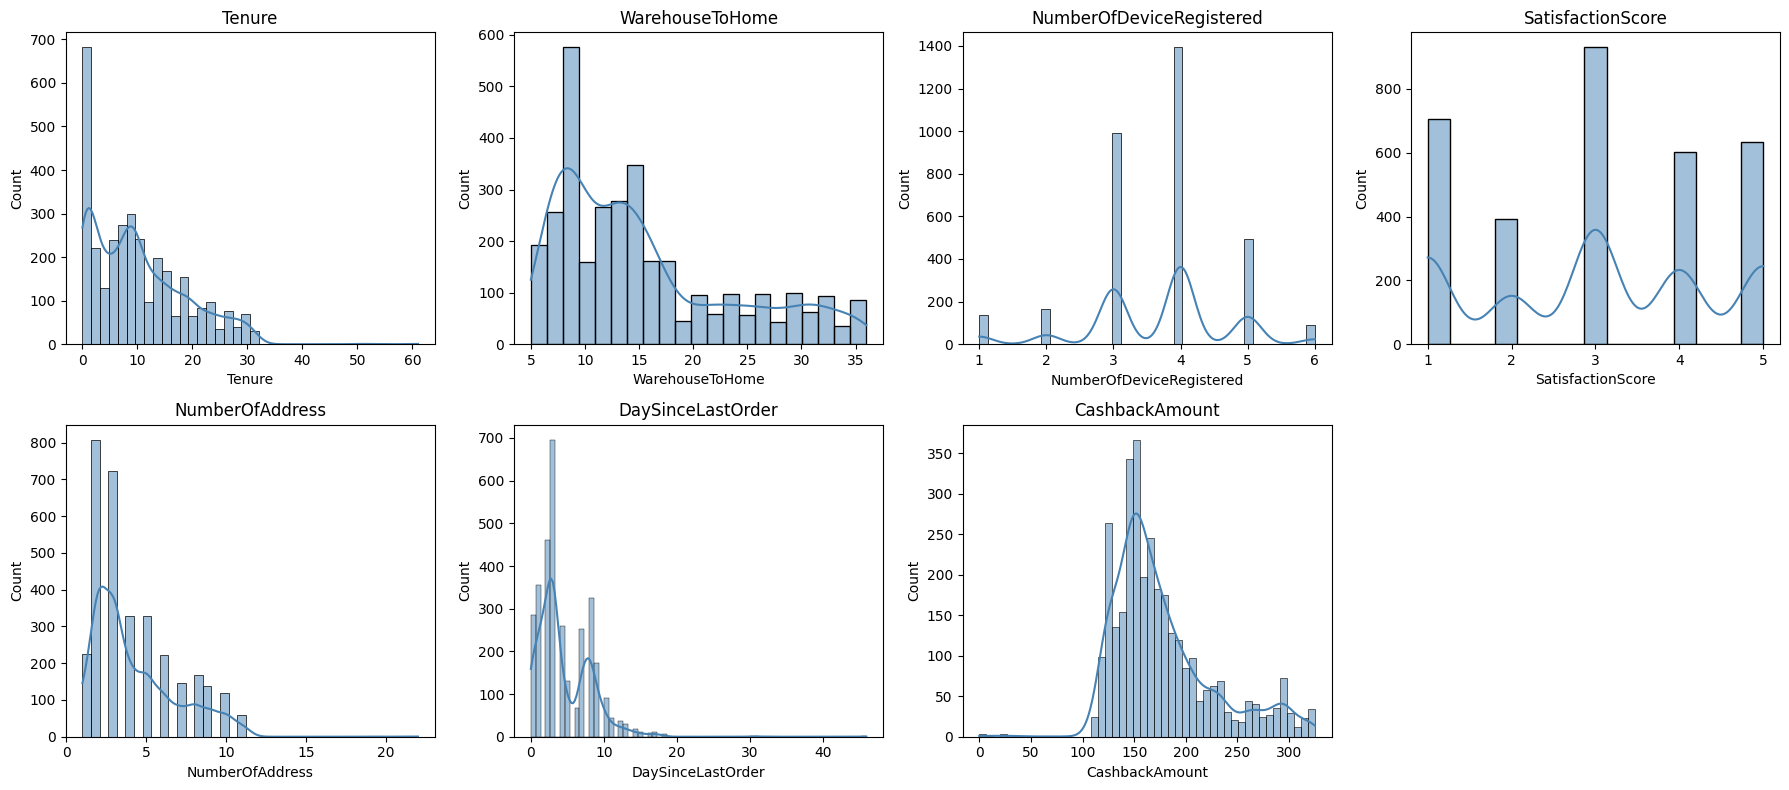

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(col)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

`Tenure`, `DaySinceLastOrder`, and `CashbackAmount` are right-skewed - most customers cluster at lower values with a smaller number of longer-tenured, higher-spending customers pulling the tail out. `WarehouseToHome` is fairly evenly spread between 5 and 36 (its one extreme value was already removed in Task 1). `NumberOfDeviceRegistered` and `SatisfactionScore` are narrow, discrete scales, so their histograms show a handful of bars rather than a continuous shape.

## Boxplots

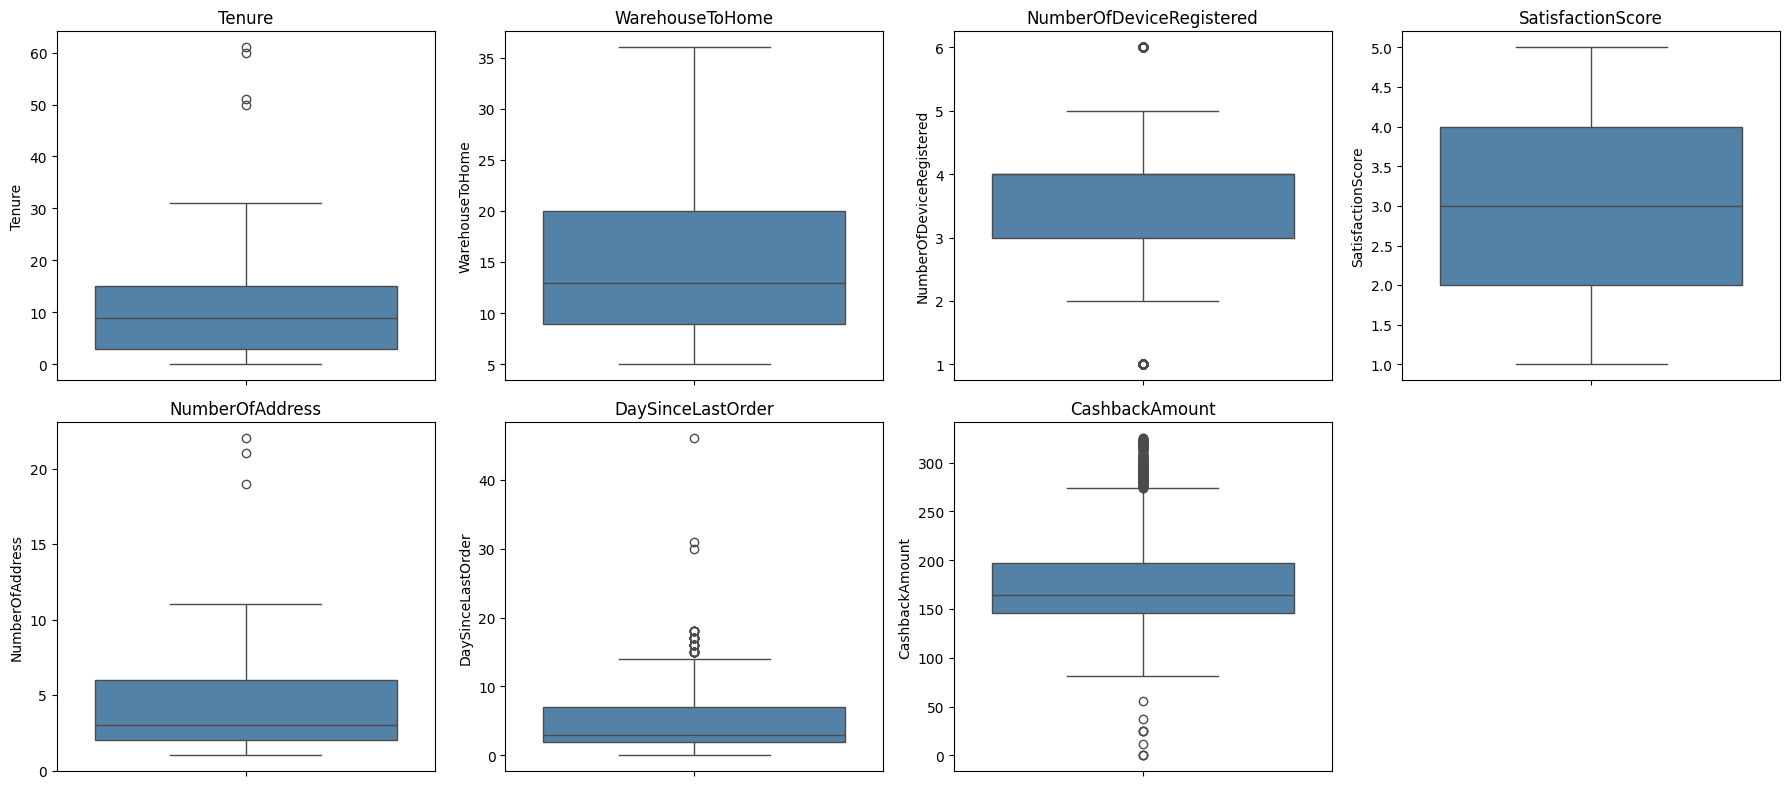

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.boxplot(y=df[col], ax=axes[i], color="steelblue")
    axes[i].set_title(col)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

`CashbackAmount` and `DaySinceLastOrder` show the most flagged points on the boxplots, consistent with their right skew above. Task 1 already inspected these specific columns and found the flagged values to be realistic, not data errors, so no further removal is done here.

## Categorical Feature Distributions
The categorical columns were already one-hot encoded in Task 1, so their distributions are read from the encoded columns rather than raw category labels.

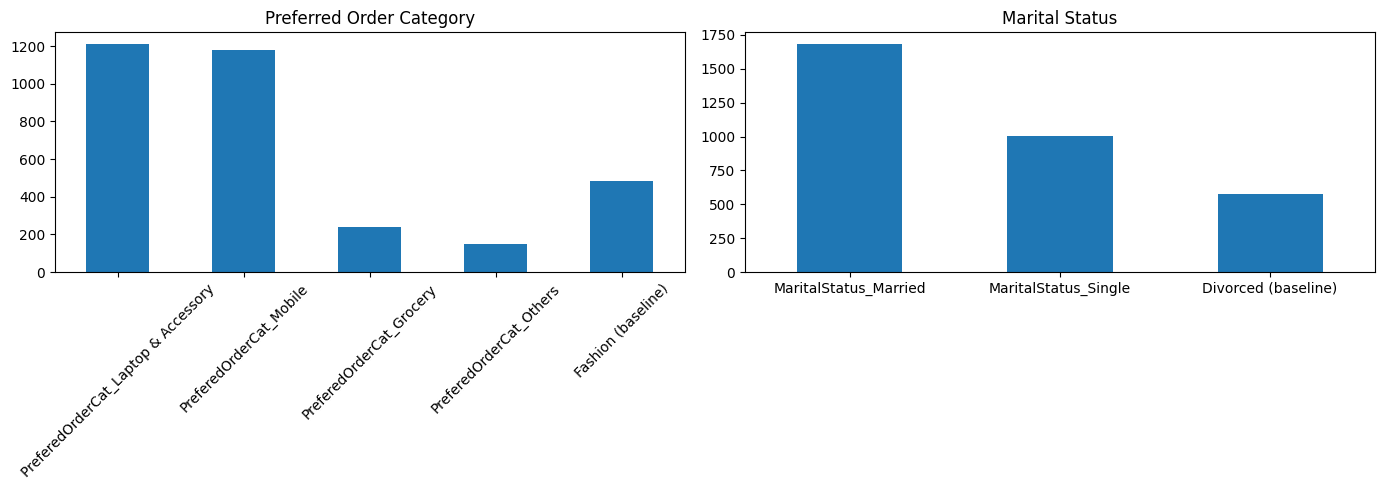

In [8]:
order_cat_cols = [c for c in df.columns if c.startswith("PreferedOrderCat_")]
marital_cols = [c for c in df.columns if c.startswith("MaritalStatus_")]

order_cat_counts = df[order_cat_cols].sum().sort_values(ascending=False)
order_cat_counts["Fashion (baseline)"] = df.shape[0] - df[order_cat_cols].sum().sum()

marital_counts = df[marital_cols].sum().sort_values(ascending=False)
marital_counts["Divorced (baseline)"] = df.shape[0] - df[marital_cols].sum().sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_cat_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Preferred Order Category")
axes[0].tick_params(axis="x", rotation=45)

marital_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Marital Status")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

"Laptop & Accessory" and "Mobile" are the two most common preferred order categories (note: "Mobile" here already includes the "Mobile Phone" entries merged in Task 1). Married customers make up the largest marital status group, followed by Single and Divorced.

## Churn Distribution

In [9]:
churn_counts = df["Churn"].value_counts()
churn_rate = df["Churn"].mean()

print(churn_counts)
print(f"\nOverall churn rate: {churn_rate:.1%}")

Churn
0    2734
1     533
Name: count, dtype: int64

Overall churn rate: 16.3%


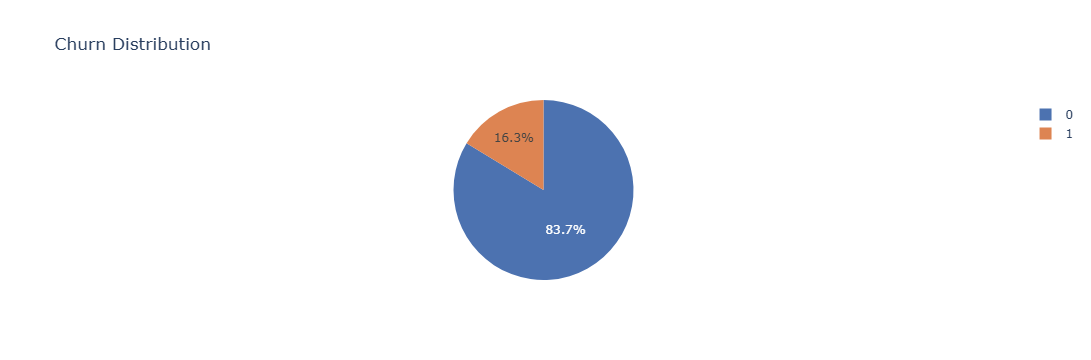

In [10]:
fig = px.pie(df, names="Churn", title="Churn Distribution",
             color_discrete_sequence=["#4C72B0", "#DD8452"])
fig.show()

Churn is imbalanced in this dataset - about 16% of customers churned, 84% did not. Any grouped comparison below should be read with that base rate in mind.

## Correlation Matrix and Heatmap

In [11]:
corr_matrix = df[numeric_features + ["Complain", "Churn"]].corr()
corr_matrix.round(2)

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,DaySinceLastOrder,CashbackAmount,Complain,Churn
Tenure,1.00,-0.03,-0.04,-0.03,0.23,0.16,0.46,-0.02,-0.34
WarehouseToHome,-0.03,1.00,0.02,0.01,-0.01,0.03,0.01,0.05,0.07
NumberOfDeviceRegistered,-0.04,0.02,1.00,-0.01,0.08,0.00,0.12,0.01,0.11
SatisfactionScore,-0.03,0.01,-0.01,1.00,0.04,0.04,0.01,-0.04,0.10
NumberOfAddress,0.23,-0.01,0.08,0.04,1.00,-0.07,0.19,-0.01,0.05
DaySinceLastOrder,0.16,0.03,0.00,0.04,-0.07,1.00,0.31,-0.05,-0.14
CashbackAmount,0.46,0.01,0.12,0.01,0.19,0.31,1.00,-0.00,-0.15
Complain,-0.02,0.05,0.01,-0.04,-0.01,-0.05,-0.00,1.00,0.26
Churn,-0.34,0.07,0.11,0.10,0.05,-0.14,-0.15,0.26,1.00


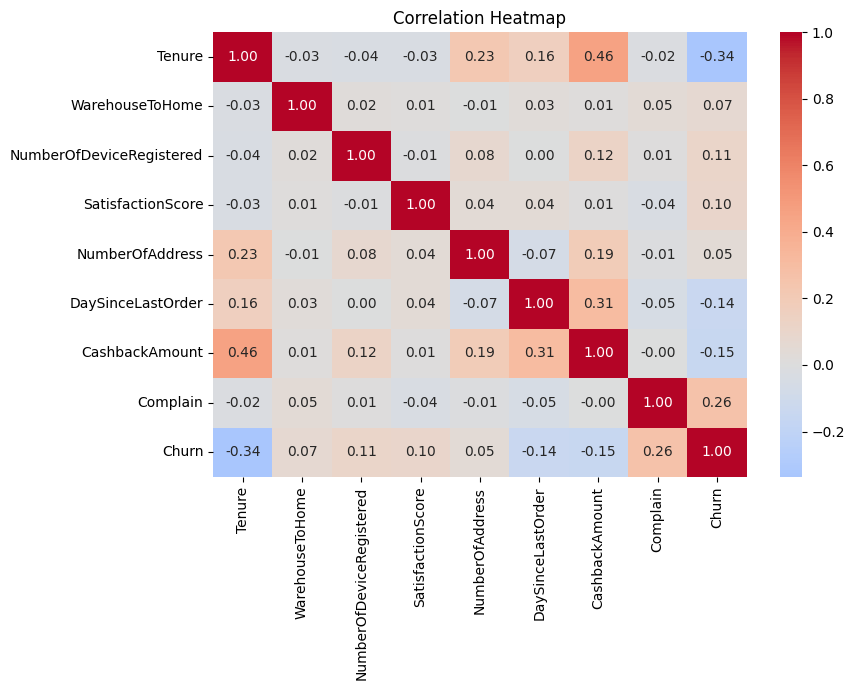

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

`Tenure` has the strongest relationship with `Churn` of any numeric feature here (-0.34) - customers with lower tenure show a higher observed churn rate in this dataset. `Complain` is also fairly strongly associated with churn (0.25 or so, visible in the heatmap). `CashbackAmount` and `DaySinceLastOrder` show weaker negative correlations. None of the other numerical features correlate strongly with churn on their own.

## Group Comparisons

In [13]:
complain_rate = df.groupby("Complain")["Churn"].mean()
print("Churn rate by Complain flag:")
print(complain_rate.round(3))

Churn rate by Complain flag:
Complain
0    0.102
1    0.318
Name: Churn, dtype: float64


In [14]:
tenure_by_churn = df.groupby("Churn")["Tenure"].median()
print("Median Tenure by Churn:")
print(tenure_by_churn)

Median Tenure by Churn:
Churn
0    9.0
1    1.0
Name: Tenure, dtype: float64


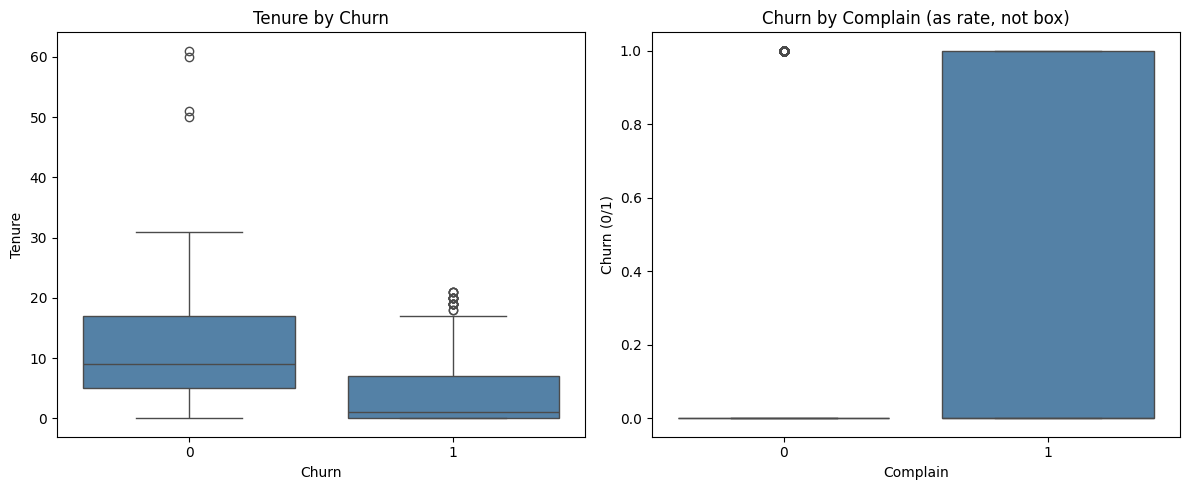

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Churn", y="Tenure", ax=axes[0], color="steelblue")
axes[0].set_title("Tenure by Churn")

sns.boxplot(data=df, x="Complain", y="Churn", ax=axes[1], color="steelblue")
axes[1].set_title("Churn by Complain (as rate, not box)")
axes[1].set_ylabel("Churn (0/1)")

plt.tight_layout()
plt.show()

Customers who churned have a much lower median tenure (1) than those who didn't (9), matching the correlation above. Customers who filed a complaint churn at roughly 3x the rate of those who didn't (about 32% vs 10%).

In [16]:
order_cat_churn = {}
for c in order_cat_cols:
    order_cat_churn[c.replace("PreferedOrderCat_", "")] = df.loc[df[c] == 1, "Churn"].mean()
order_cat_churn["Fashion (baseline)"] = df.loc[df[order_cat_cols].sum(axis=1) == 0, "Churn"].mean()

order_cat_churn = pd.Series(order_cat_churn).sort_values(ascending=False)
print("Churn rate by preferred order category:")
print(order_cat_churn.round(3))

Churn rate by preferred order category:
Mobile                0.269
Fashion (baseline)    0.155
Laptop & Accessory    0.098
Others                0.074
Grocery               0.042
dtype: float64


Customers whose preferred category is "Mobile" show the highest observed churn rate (about 27%), well above categories like "Grocery" (about 4%). This is an association in this dataset, not a claim that ordering mobile products causes churn.

## Pairplot
Using a small, meaningful subset of numerical features so the plot stays readable.

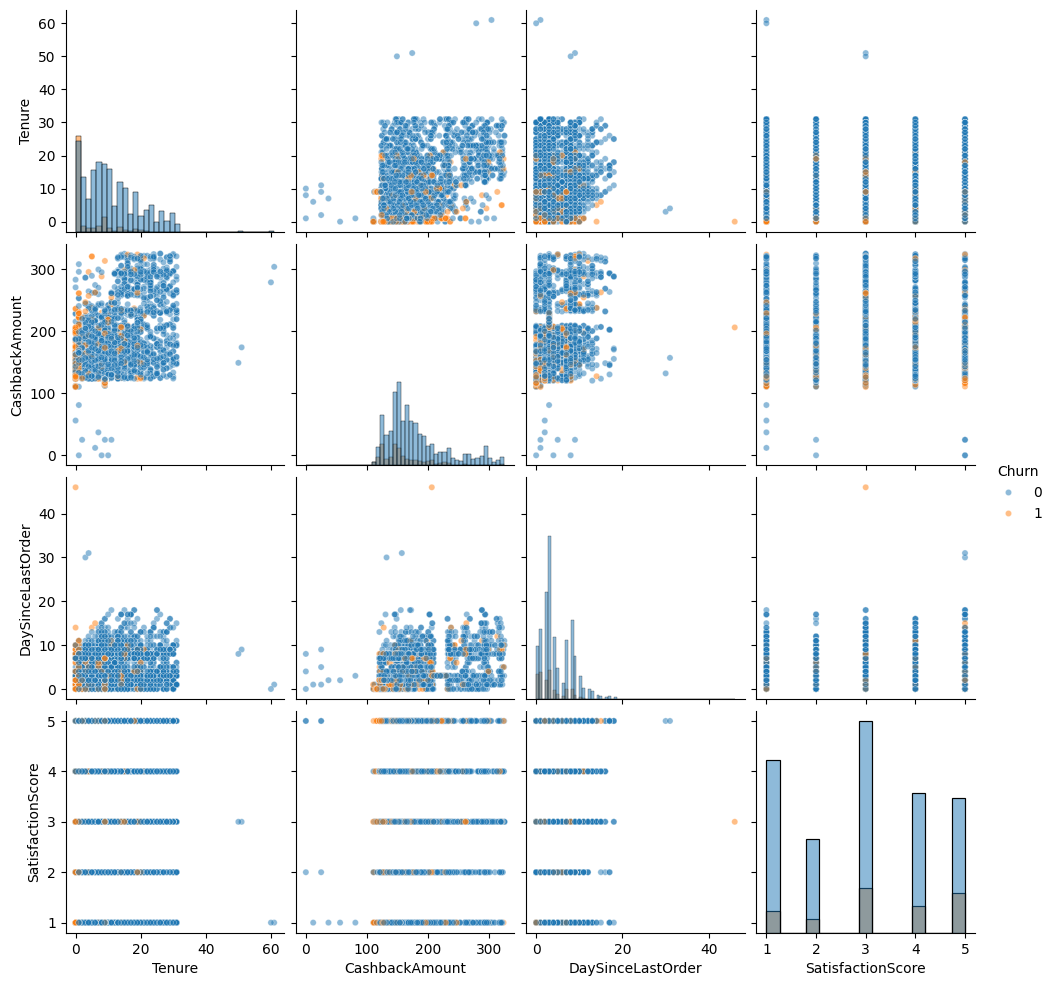

In [17]:
pairplot_features = ["Tenure", "CashbackAmount", "DaySinceLastOrder", "SatisfactionScore"]

sns.pairplot(df, vars=pairplot_features, hue="Churn", diag_kind="hist",
             plot_kws={"alpha": 0.5, "s": 20})
plt.show()

Churned customers (orange) cluster visibly toward the low end of `Tenure` across every panel involving it - the clearest separation in the pairplot. `CashbackAmount` and `DaySinceLastOrder` show a much weaker, less visually distinct split. `SatisfactionScore` doesn't show any obvious separation by churn here.

## Patterns, Trends, and Feature-Level Inferences

Based on the actual outputs above:

- **Tenure is the strongest single signal found**: customers with lower tenure show a clearly higher observed churn rate (median tenure 1 for churned customers vs 9 for retained ones, correlation -0.34).
- **Complaints matter**: customers who filed a complaint churn at roughly 3x the rate of those who didn't (about 32% vs 10%).
- **Preferred order category shows a real spread**: customers whose preferred category is "Mobile" have a notably higher observed churn rate (~27%) than most other categories (e.g. "Grocery" at ~4%).
- **Marital status shows a pattern**: single customers churn more often (~26%) than married customers (~11%).
- **CashbackAmount and DaySinceLastOrder are weakly associated with churn** (correlations around -0.15), in the same direction as tenure - customers who churn tend to have received somewhat less cashback and ordered somewhat more recently before leaving.
- **SatisfactionScore, WarehouseToHome, NumberOfAddress, and NumberOfDeviceRegistered show little to no relationship with churn** in this dataset - their correlations with `Churn` are all close to zero.
- These are observed associations, not proof of cause and effect. For example, low tenure and higher churn may both stem from a customer's overall engagement with the platform, rather than tenure directly causing churn.

## Final EDA Conclusion

The cleaned dataset has 3,267 rows and 15 columns, no missing values, and no duplicate rows. Overall churn is imbalanced at about 16%. The most notable patterns found are that customers with lower tenure, customers who have filed a complaint, and customers whose preferred order category is "Mobile" all show a higher observed churn rate in this dataset. No single feature explains churn on its own, but tenure and complaint history stand out as the clearest associations among the features examined.